In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the original dataset
data = pd.read_excel("Folds5x2_pp.xlsx", sheet_name=0)

# Remove duplicate rows
clean_data = data.drop_duplicates().copy()

# Define input features and output target
X = clean_data[["AT", "V", "AP", "RH"]]
y = clean_data["PE"]

# Use exactly the same data split as previous notebooks
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Check dataset sizes
print("Final Test Data Preparation:")
print("Cleaned dataset:", clean_data.shape)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# Check input features
print("\nInput Features:")
print(X.columns.tolist())

Final Test Data Preparation:
Cleaned dataset: (9527, 5)
Training samples: 6668
Validation samples: 1429
Test samples: 1430

Input Features:
['AT', 'V', 'AP', 'RH']


In [3]:
# Model 1: Mean Baseline
baseline_mean = y_train.mean()
baseline_test_pred = np.full(len(y_test), baseline_mean)

# Model 2: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_test_pred = linear_model.predict(X_test)

# Model 3: Decision Tree (Depth = 8)
final_tree = DecisionTreeRegressor(
    max_depth=8,
    random_state=42
)

final_tree.fit(X_train, y_train)
tree_test_pred = final_tree.predict(X_test)

# Calculate evaluation metrics
model_names = [
    "Mean Baseline",
    "Linear Regression",
    "Decision Tree (Depth 8)"
]

predictions = [
    baseline_test_pred,
    linear_test_pred,
    tree_test_pred
]

test_results = []

for name, pred in zip(model_names, predictions):

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    test_results.append({
        "Model": name,
        "Test MAE (MW)": mae,
        "Test RMSE (MW)": rmse,
        "Test R2": r2
    })

# Display final results
test_results_df = pd.DataFrame(test_results)

print("Final Test Set Results:")
display(test_results_df.round(3))

Final Test Set Results:


,Model,Test MAE (MW),Test RMSE (MW),Test R2
0,Mean Baseline,14.880,17.153,-0.000
1,Linear Regression,3.756,4.744,0.924
2,Decision Tree (Depth 8),3.194,4.330,0.936


In [4]:
# Define the two regression models
models_to_compare = {
    "Linear Regression": linear_model,
    "Decision Tree (Depth 8)": final_tree
}

comparison_results = []

for name, model in models_to_compare.items():

    # Predict validation and test data
    val_predictions = model.predict(X_val)
    test_predictions = model.predict(X_test)

    # Calculate validation errors
    val_mae = mean_absolute_error(y_val, val_predictions)
    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_predictions)
    )

    # Calculate test errors
    test_mae = mean_absolute_error(y_test, test_predictions)
    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    # Store results
    comparison_results.append({
        "Model": name,
        "Validation MAE": val_mae,
        "Test MAE": test_mae,
        "MAE Difference": test_mae - val_mae,
        "Validation RMSE": val_rmse,
        "Test RMSE": test_rmse,
        "RMSE Difference": test_rmse - val_rmse
    })

# Create comparison table
final_comparison_df = pd.DataFrame(comparison_results)

print("Validation vs Test Comparison:")
display(final_comparison_df.round(3))

Validation vs Test Comparison:


,Model,Validation MAE,Test MAE,MAE Difference,Validation RMSE,Test RMSE,RMSE Difference
0,Linear Regression,3.587,3.756,0.169,4.630,4.744,0.113
1,Decision Tree (Depth 8),3.070,3.194,0.123,4.244,4.330,0.086


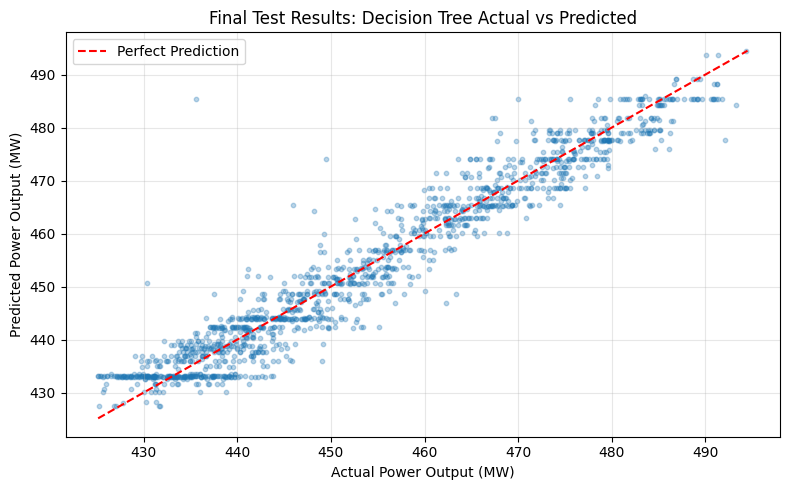

In [5]:
plt.figure(figsize=(8, 5))

# Plot actual and predicted values for the test set
plt.scatter(
    y_test,
    tree_test_pred,
    alpha=0.3,
    s=10
)

# Define the range for the perfect prediction line
minimum = min(y_test.min(), tree_test_pred.min())
maximum = max(y_test.max(), tree_test_pred.max())

# Draw the perfect prediction line
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Power Output (MW)")
plt.ylabel("Predicted Power Output (MW)")
plt.title("Final Test Results: Decision Tree Actual vs Predicted")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Calculate residuals for the final decision tree
test_residuals = y_test.to_numpy() - tree_test_pred

# Calculate absolute prediction errors
absolute_errors = np.abs(test_residuals)

# Calculate error statistics
mean_residual = np.mean(test_residuals)
max_absolute_error = np.max(absolute_errors)

# Count predictions with absolute errors greater than 10 MW
large_errors = np.sum(absolute_errors > 10)
large_error_percentage = large_errors / len(y_test) * 100

# Display results
print("Final Decision Tree Error Analysis:")
print(f"Mean Residual: {mean_residual:.3f} MW")
print(f"Maximum Absolute Error: {max_absolute_error:.3f} MW")
print(f"Predictions with Error > 10 MW: {large_errors}")
print(f"Percentage with Error > 10 MW: {large_error_percentage:.2f}%")

Final Decision Tree Error Analysis:
Mean Residual: 0.063 MW
Maximum Absolute Error: 49.895 MW
Predictions with Error > 10 MW: 29
Percentage with Error > 10 MW: 2.03%
